In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("Mall_Customers.xls")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [3]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original Feature Shape:", X.shape)
print("Scaled Feature Shape:", X_scaled.shape)
print("\nFirst 5 standardized rows:")
print(pd.DataFrame(X_scaled, columns=X.columns).head())

Original Feature Shape: (200, 2)
Scaled Feature Shape: (200, 2)

First 5 standardized rows:
   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980


In [4]:
K_range = range(2, 11)

wcss = []
silhouette_scores = []

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    wcss.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

results = pd.DataFrame({
    'k': list(K_range),
    'WCSS (Inertia)': wcss,
    'Silhouette Score': silhouette_scores
})

print("--- Cluster Evaluation Metrics across k ---")
print(results.to_string(
    index=False,
    formatters={
        'WCSS (Inertia)': '{:.2f}'.format,
        'Silhouette Score': '{:.4f}'.format
    }
))

--- Cluster Evaluation Metrics across k ---
 k WCSS (Inertia) Silhouette Score
 2         269.69           0.3213
 3         157.70           0.4666
 4         108.92           0.4939
 5          65.57           0.5547
 6          55.06           0.5399
 7          44.86           0.5281
 8          37.23           0.4552
 9          32.39           0.4571
10          29.98           0.4432


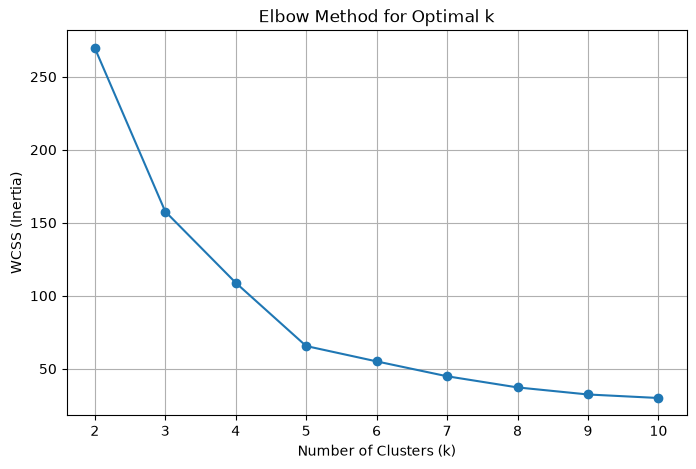

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(list(K_range), wcss, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

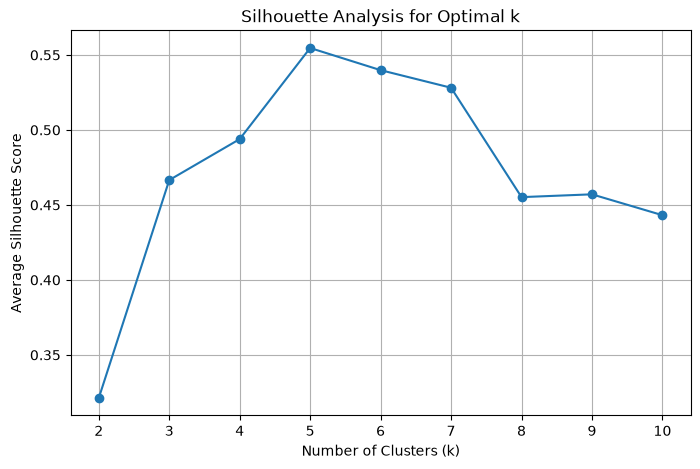

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(list(K_range), silhouette_scores, marker='o')
plt.title('Silhouette Analysis for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

In [7]:
optimal_k = 5

final_kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42,
    n_init=10
)

df['Cluster'] = final_kmeans.fit_predict(X_scaled)

print("Optimal Number of Clusters:", optimal_k)
print("\nCluster-wise customer counts:")
print(df['Cluster'].value_counts().sort_index())

print("\nFirst 10 customer records with cluster labels:")
print(df.head(10))

Optimal Number of Clusters: 5

Cluster-wise customer counts:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

First 10 customer records with cluster labels:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

  

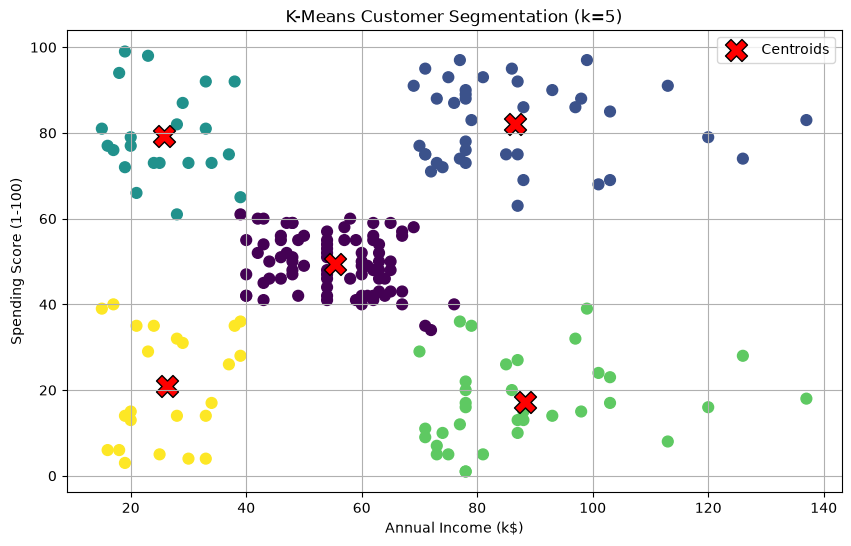

In [8]:
centers = scaler.inverse_transform(final_kmeans.cluster_centers_)

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Annual Income (k$)'],
    df['Spending Score (1-100)'],
    c=df['Cluster'],
    cmap='viridis',
    s=60
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    s=250,
    c='red',
    edgecolors='black',
    label='Centroids'
)

plt.title('K-Means Customer Segmentation (k=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
print("     FINAL RESULTS     ")
print("Optimal Number of Clusters:", optimal_k)
print("Best Silhouette Score:", round(max(silhouette_scores), 4))
print("Number of Customers:", len(df))


     FINAL RESULTS     
Optimal Number of Clusters: 5
Best Silhouette Score: 0.5547
Number of Customers: 200


In [10]:
print("Name :Manthan Mishra")
print ("PRN No.:72421206B")

Name :Manthan Mishra
PRN No.:72421206B
